In [167]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("/content/gurgaon_city.csv")

## 1. Initial Data Exploration

In [168]:
# Display basic information about the DataFrame
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  int64  
 3   total_rooms         20640 non-null  int64  
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  int64  
 6   households          20640 non-null  int64  
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  int64  
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(4), int64(5), object(1)
memory usage: 1.6+ MB


None

In [169]:
# Check for missing values
display(df.isnull().sum())

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [170]:
df.shape

(20640, 10)

## 2. Data Cleaning - Handling Missing Values

In [171]:
# Impute missing values in 'total_bedrooms' with the median
median_bedrooms = df['total_bedrooms'].median()
df['total_bedrooms'].fillna(median_bedrooms, inplace=True)

# Verify that there are no more missing values in 'total_bedrooms'
print(f"Missing values in 'total_bedrooms' after imputation: {df['total_bedrooms'].isnull().sum()}")

Missing values in 'total_bedrooms' after imputation: 0


/tmp/ipykernel_1176/1319608930.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['total_bedrooms'].fillna(median_bedrooms, inplace=True)


In [172]:
# Display the first few rows of the DataFrame after imputation
display(df.head())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41,880,129.0,322,126,8.3252,452600,NEAR BAY
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,358500,NEAR BAY
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,352100,NEAR BAY
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,341300,NEAR BAY
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,342200,NEAR BAY


## 3. Descriptive Statistics

In [173]:
# Display descriptive statistics for numerical columns
display(df.describe())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,536.838857,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,419.391878,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,297.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,643.250000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


## 4. Feature Engineering

Let's create some new features that might be useful for our model, such as ratios of rooms, bedrooms, and population per household.

In [174]:
# Create new features
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
df['population_per_household'] = df['population'] / df['households']

# Display the first few rows with new features
display(df.head())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41,880,129.0,322,126,8.3252,452600,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,358500,NEAR BAY,6.238137,0.155797,2.109842
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,352100,NEAR BAY,8.288136,0.129516,2.802260
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,341300,NEAR BAY,5.817352,0.184458,2.547945
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,342200,NEAR BAY,6.281853,0.172096,2.181467


## 5. Exploratory Data Analysis (EDA)

Now, let's visualize the data to understand distributions, relationships, and potential patterns. We'll start with histograms of key numerical features and then look at some scatter plots.

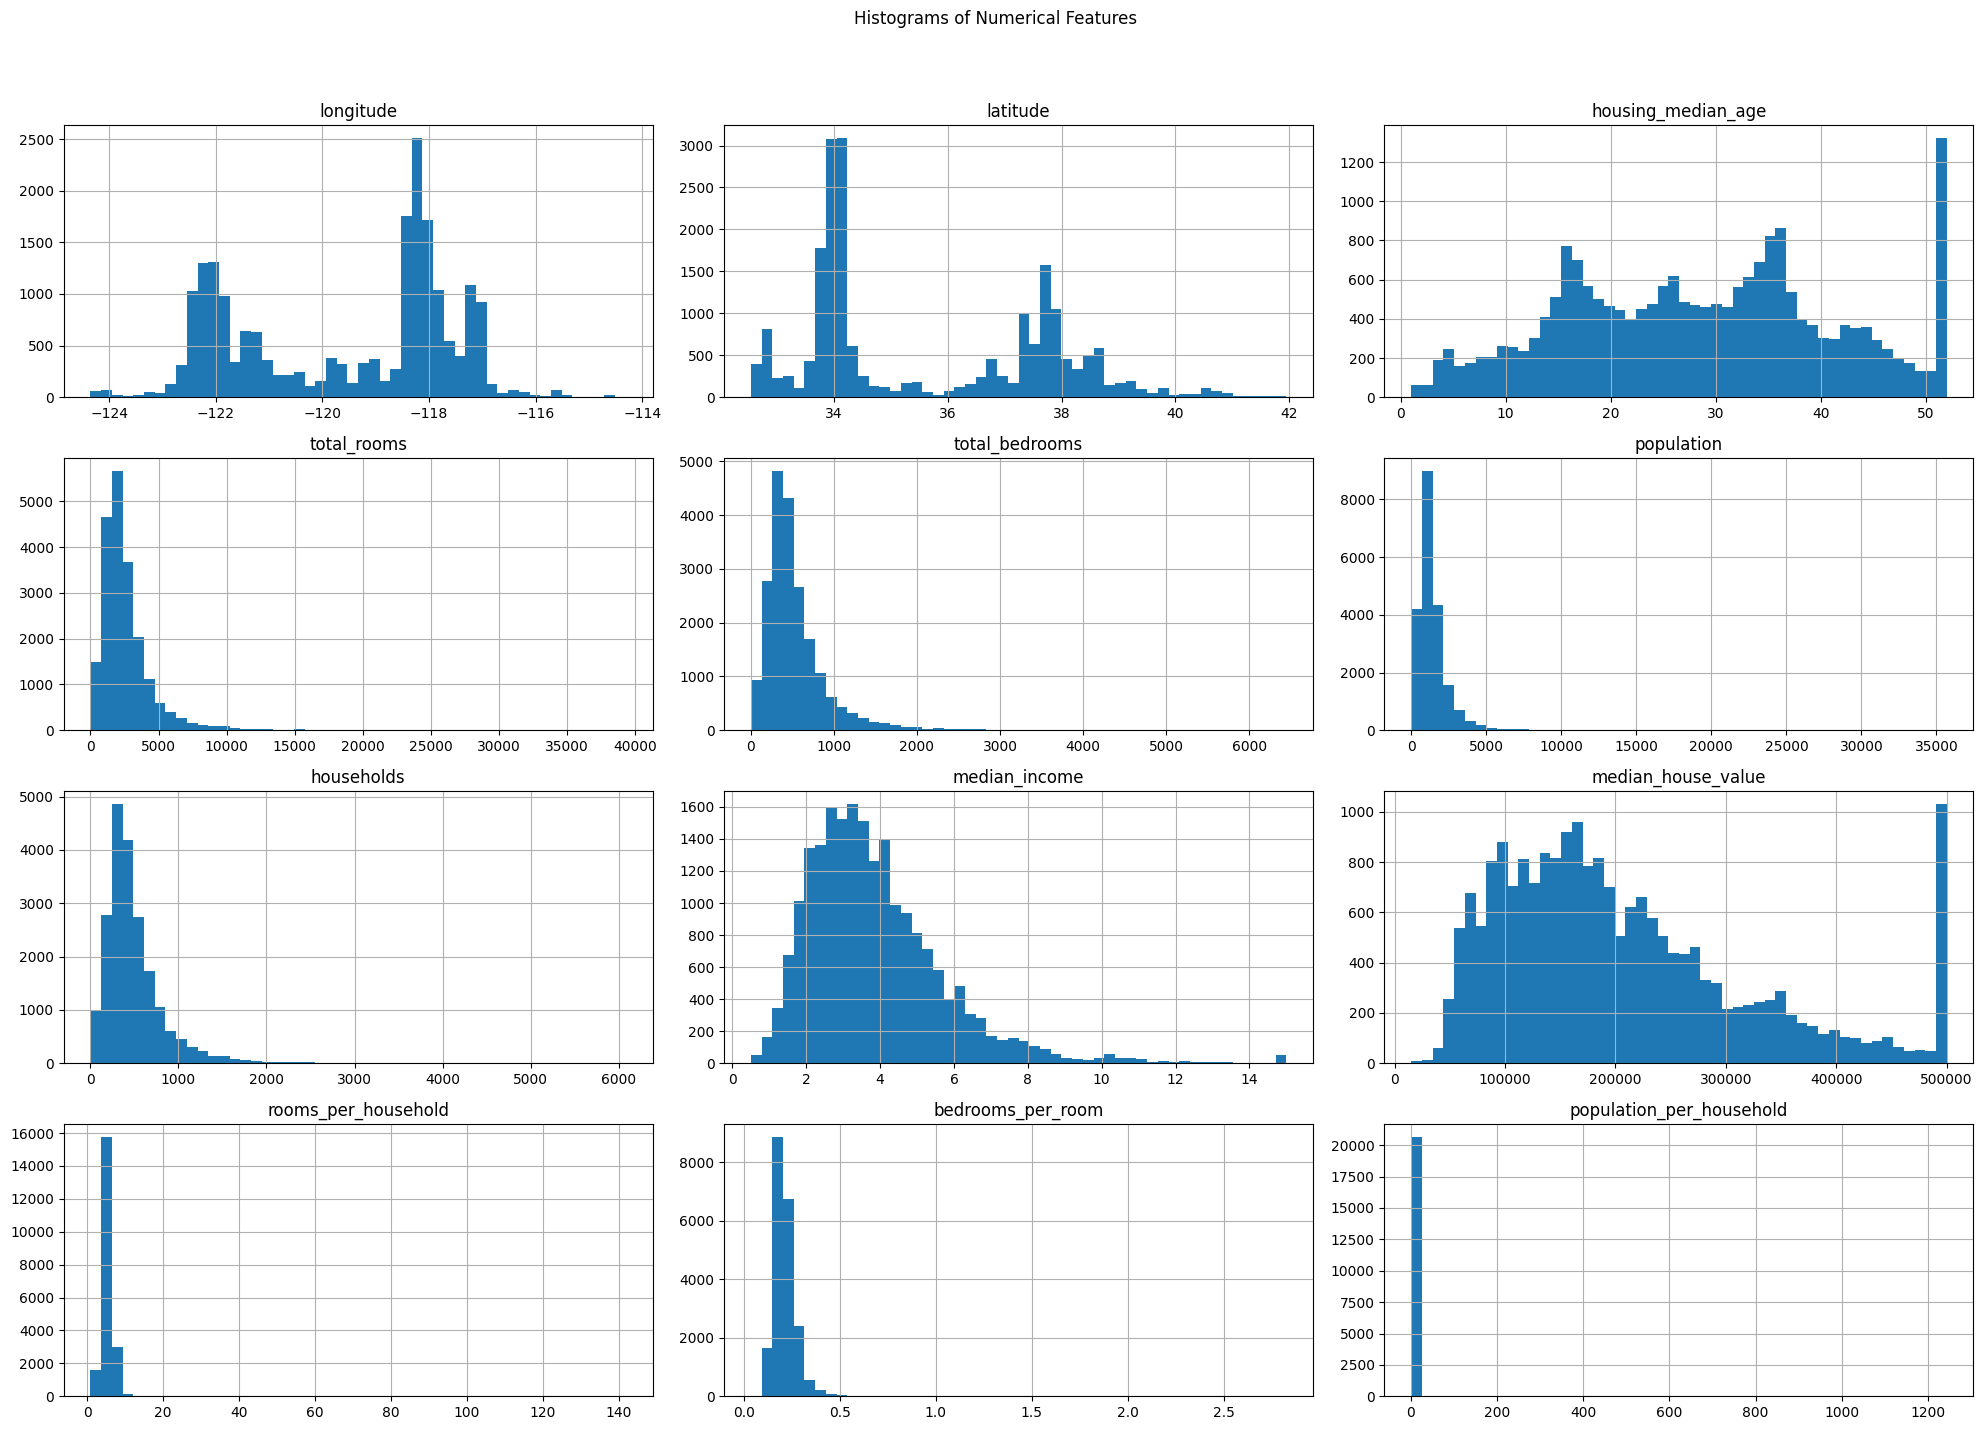

In [175]:
# Plot histograms for numerical features
df.hist(bins=50, figsize=(20, 15))
plt.suptitle('Histograms of Numerical Features')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

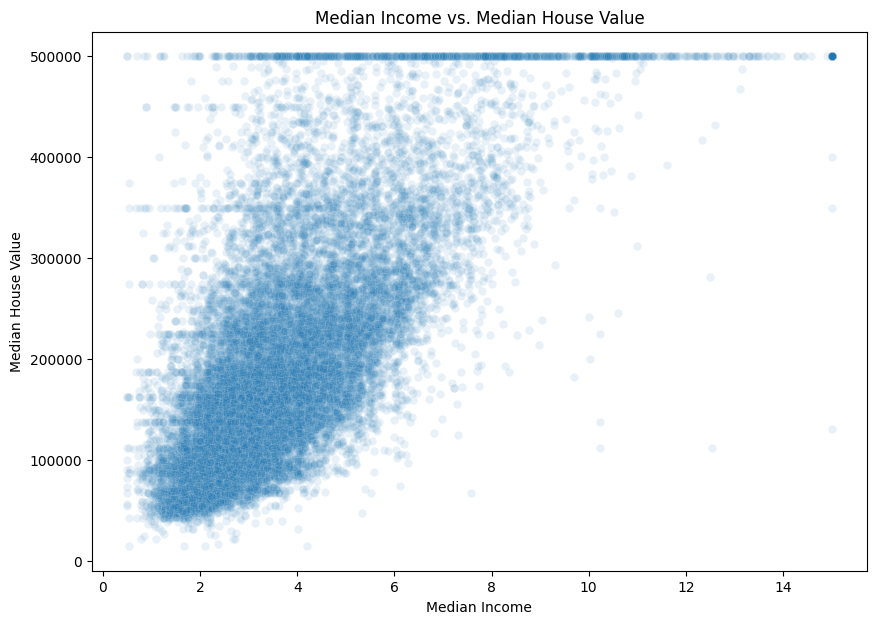

In [176]:
# Scatter plot of median_income vs. median_house_value
plt.figure(figsize=(10, 7))
sns.scatterplot(x='median_income', y='median_house_value', data=df, alpha=0.1)
plt.title('Median Income vs. Median House Value')
plt.xlabel('Median Income')
plt.ylabel('Median House Value')
plt.show()

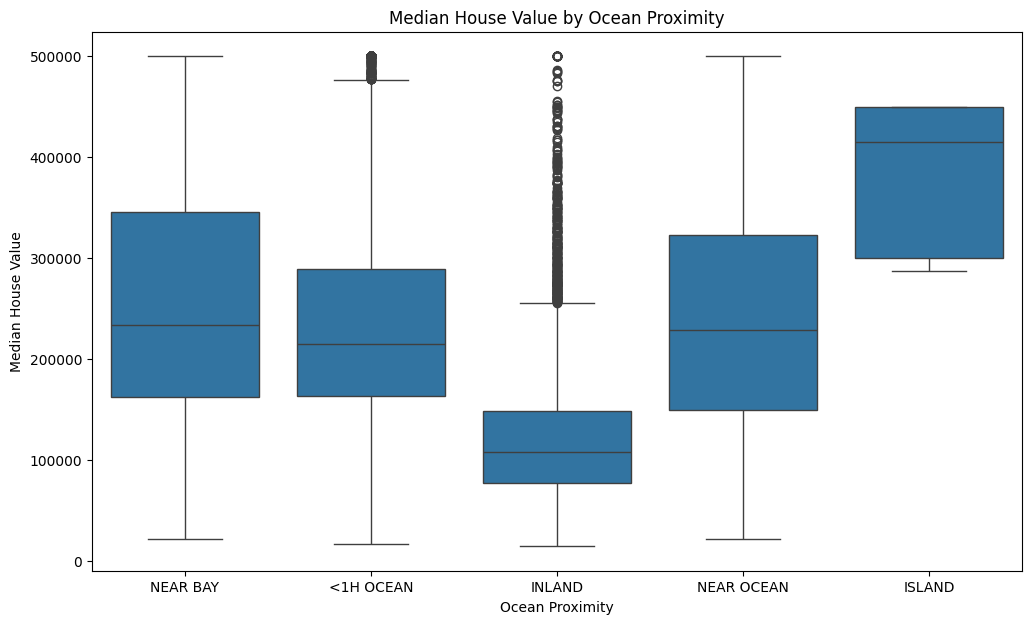

In [177]:
# Box plot of ocean_proximity vs. median_house_value
plt.figure(figsize=(12, 7))
sns.boxplot(x='ocean_proximity', y='median_house_value', data=df)
plt.title('Median House Value by Ocean Proximity')
plt.xlabel('Ocean Proximity')
plt.ylabel('Median House Value')
plt.show()

## 6. Correlation Analysis

Let's examine the correlation matrix to understand the relationships between numerical features and the target variable (`median_house_value`).

In [178]:
# Calculate the correlation matrix
corr_matrix = df.corr(numeric_only=True)

# Display correlations with median_house_value
print("Correlation with median_house_value:")
display(corr_matrix['median_house_value'].sort_values(ascending=False))

Correlation with median_house_value:


,median_house_value
median_house_value,1.000000
median_income,0.688075
rooms_per_household,0.151948
total_rooms,0.134153
housing_median_age,0.105623
households,0.065843
total_bedrooms,0.049457
population_per_household,-0.023737
population,-0.024650
longitude,-0.045967


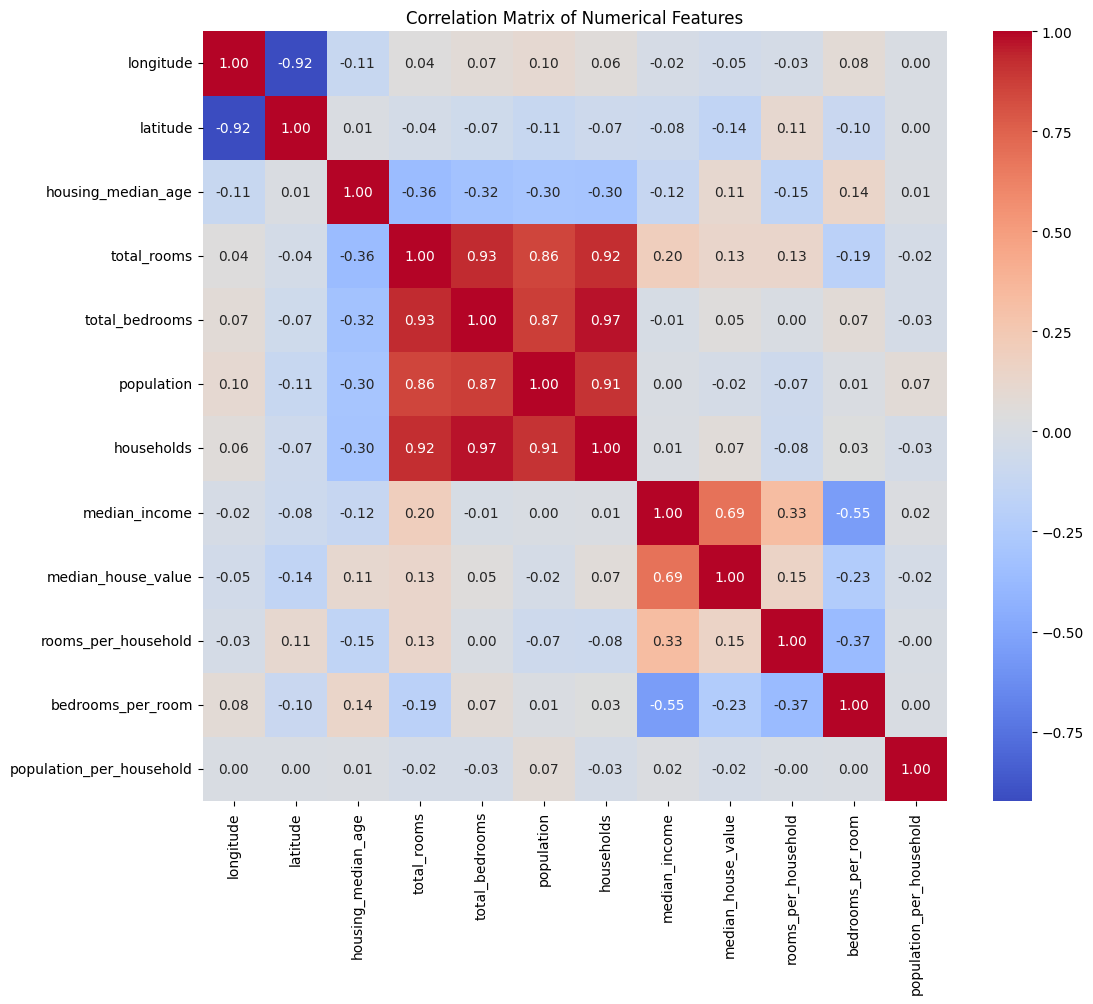

In [179]:
# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

## 7. Handling Categorical Features

The `ocean_proximity` column is a categorical feature. We need to convert it into a numerical format that machine learning models can understand. One-Hot Encoding is a common technique for this.

In [180]:
# Apply One-Hot Encoding to 'ocean_proximity'
df = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True)

# Display the first few rows of the DataFrame after one-hot encoding
print("DataFrame after One-Hot Encoding:")
display(df.head())

DataFrame after One-Hot Encoding:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,rooms_per_household,bedrooms_per_room,population_per_household,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41,880,129.0,322,126,8.3252,452600,6.984127,0.146591,2.555556,False,False,True,False
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,358500,6.238137,0.155797,2.109842,False,False,True,False
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,352100,8.288136,0.129516,2.802260,False,False,True,False
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,341300,5.817352,0.184458,2.547945,False,False,True,False
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,342200,6.281853,0.172096,2.181467,False,False,True,False


## 8. Data Preparation for Machine Learning

Before training a model, we need to split our data into features (X) and the target variable (y), and then divide it into training and testing sets. We also need to scale our numerical features.

In [181]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Define features (X) and target (y)
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (16512, 15)
X_test shape: (4128, 15)
y_train shape: (16512,)
y_test shape: (4128,)


In [182]:
# Identify numerical columns for scaling
numerical_cols = X_train.select_dtypes(include=np.number).columns

# Initialize StandardScaler
scaler = StandardScaler()

# Apply scaling to numerical columns in training and test sets
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

print("Features scaled successfully. Displaying a sample of scaled training data:")
display(X_train.head())

Features scaled successfully. Displaying a sample of scaled training data:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,rooms_per_household,bedrooms_per_room,population_per_household,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
14196,1.272587,-1.372811,0.348490,0.222569,0.211228,0.768276,0.322906,-0.326196,-0.174916,-0.211785,0.051376,False,False,False,True
8267,0.709162,-0.876696,1.618118,0.340293,0.593094,-0.098901,0.672027,-0.035843,-0.402835,0.342185,-0.117362,False,False,False,True
17445,-0.447603,-0.460146,-1.952710,-0.342597,-0.495226,-0.449818,-0.430461,0.144701,0.088216,-0.661658,-0.032280,False,False,False,True
14265,1.232698,-1.382172,0.586545,-0.561490,-0.409306,-0.007434,-0.380587,-1.017864,-0.600015,0.783032,0.077507,False,False,False,True
2271,-0.108551,0.532084,1.142008,-0.119565,-0.256559,-0.485877,-0.314962,-0.171488,0.349007,-0.550364,-0.068832,True,False,False,False


## 9. Model Training and Evaluation (Linear Regression Baseline)

Let's train a simple Linear Regression model and evaluate its performance as a baseline.

Linear Regression Model Performance:
Mean Squared Error (MSE): 5280716470.09
Root Mean Squared Error (RMSE): 72668.54
R-squared (R2) Score: 0.60


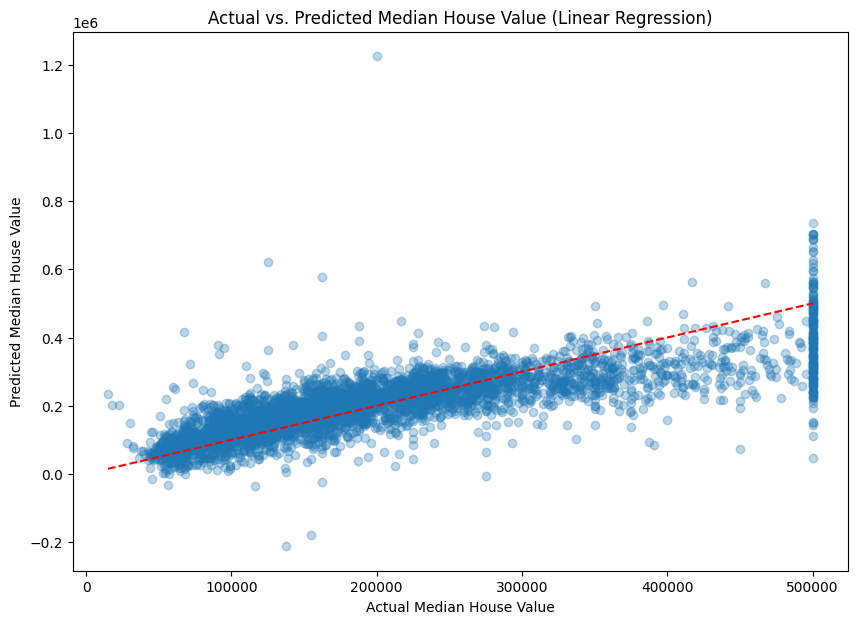

In [183]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Initialize and train the Linear Regression model
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

# Make predictions on the test set
y_pred_lr = lin_reg.predict(X_test)

# Evaluate the model
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print(f"Linear Regression Model Performance:")
print(f"Mean Squared Error (MSE): {mse_lr:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse_lr:.2f}")
print(f"R-squared (R2) Score: {r2_lr:.2f}")

# Plot actual vs. predicted values
plt.figure(figsize=(10, 7))
plt.scatter(y_test, y_pred_lr, alpha=0.3)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.xlabel('Actual Median House Value')
plt.ylabel('Predicted Median House Value')
plt.title('Actual vs. Predicted Median House Value (Linear Regression)')
plt.show()

## 10. Model Training and Evaluation (Random Forest Regressor)

Now, let's train a more advanced model, the Random Forest Regressor, and compare its performance to the Linear Regression baseline.

Random Forest Regressor Model Performance:
Mean Squared Error (MSE): 2533204242.38
Root Mean Squared Error (RMSE): 50330.95
R-squared (R2) Score: 0.81


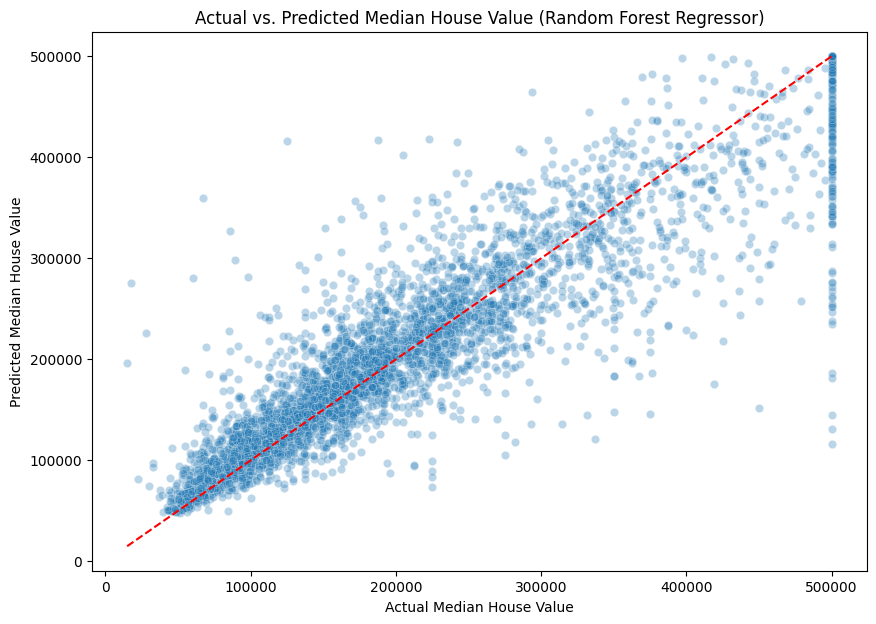

In [184]:
from sklearn.ensemble import RandomForestRegressor

# Initialize and train the Random Forest Regressor model
# Using default parameters for initial comparison
rf_reg = RandomForestRegressor(random_state=42, n_jobs=-1)
rf_reg.fit(X_train, y_train)

# Make predictions on the test set
y_pred_rf = rf_reg.predict(X_test)

# Evaluate the model
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Random Forest Regressor Model Performance:")
print(f"Mean Squared Error (MSE): {mse_rf:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse_rf:.2f}")
print(f"R-squared (R2) Score: {r2_rf:.2f}")

# Plot actual vs. predicted values for Random Forest
plt.figure(figsize=(10, 7))
sns.scatterplot(x=y_test, y=y_pred_rf, alpha=0.3)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.xlabel('Actual Median House Value')
plt.ylabel('Predicted Median House Value')
plt.title('Actual vs. Predicted Median House Value (Random Forest Regressor)')
plt.show()

### Comparison of Models

Let's summarize the performance of both models.

In [185]:
print("\n--- Model Performance Comparison ---")
print(f"Linear Regression R-squared: {r2_lr:.2f}")
print(f"Random Forest Regressor R-squared: {r2_rf:.2f}")
print(f"Linear Regression RMSE: {rmse_lr:.2f}")
print(f"Random Forest Regressor RMSE: {rmse_rf:.2f}")

if r2_rf > r2_lr:
    print("\nThe Random Forest Regressor performed better than the Linear Regression model.")
else:
    print("\nThe Linear Regression model performed better or similarly to the Random Forest Regressor.")


--- Model Performance Comparison ---
Linear Regression R-squared: 0.60
Random Forest Regressor R-squared: 0.81
Linear Regression RMSE: 72668.54
Random Forest Regressor RMSE: 50330.95

The Random Forest Regressor performed better than the Linear Regression model.
